In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sympy import symbols, Function, Eq, dsolve, lambdify, exp

In [24]:
t = symbols('t', positive=True)
s = symbols('s', positive=True)
T_start = symbols('T_start')
P = 90
t_sh = 35
t_sun = 55
tau = 30
T_sun = 80
T_sh = -40
T_0 = -20

ОДУ для уч. "свет"

In [25]:
T = Function('T')
ode_sun = Eq(T(s).diff(s) + T(s)/tau, T_sun/tau)
ode_sun

Eq(T(s)/30 + Derivative(T(s), s), 2.66666666666667)

In [26]:
sol_sun = dsolve(ode_sun, T(s), ics={T(0): T_start})
expr_sun = sol_sun.rhs
expr_sun

(T_start - 80.0)*exp(-0.0333333333333333*s) + 80.0

ОДУ для уч. "тень"

In [27]:
ode_sh = Eq(T(s).diff(s) + T(s)/tau, T_sh/tau)
ode_sh

Eq(T(s)/30 + Derivative(T(s), s), -1.33333333333333)

In [28]:
sol_sh = dsolve(ode_sh, T(s), ics={T(0): T_start})
expr_sh = sol_sh.rhs
expr_sh

(T_start + 40.0)*exp(-0.0333333333333333*s) - 40.0

In [29]:
f_sun = lambdify((s, T_start), expr_sun, 'numpy')
f_sh = lambdify((s, T_start), expr_sh, 'numpy')

In [30]:
t_global = []
T_global = []
T_current = T_0
current_time = 0.0
num_orbits = 5

Моделирование участка для солнца

In [31]:
s_vals_sun = np.linspace(0, t_sun, 200)

T_vals_sun = f_sun(s_vals_sun, T_current)
t_global.extend(current_time + s_vals_sun[1:])
T_global.extend(T_vals_sun[1:])
T_current = T_vals_sun[-1]
current_time += t_sun
print(f"Температура в конце участка: {T_current:.2f} °C")

Температура в конце участка: 64.01 °C


Моделирование уч. для тени

In [32]:
s_vals_sh = np.linspace(0, t_sh, 200)

T_vals_sh = f_sh(s_vals_sh, T_current)

t_global.extend(current_time + s_vals_sh[1:])
T_global.extend(T_vals_sh[1:])

T_current = T_vals_sh[-1]
current_time += t_sh

print(f"Температура в конце участка: {T_current:.2f} °C")

Температура в конце участка: -7.61 °C


Цикл моделирования 5-ти витков

In [33]:
t_global = []
T_global = []
T_current = T_0
current_time = 0.0

for orbit in range(num_orbits):
    # Свет
    s_sun = np.linspace(0, t_sun, 200)
    T_sun_vals = f_sun(s_sun, T_current)

    t_global.extend(current_time + s_sun[1:])
    T_global.extend(T_sun_vals[1:])

    T_current = T_sun_vals[-1]
    current_time += t_sun

    # Тень
    s_sh = np.linspace(0, t_sh, 200)
    T_sh_vals = f_sh(s_sh, T_current)

    t_global.extend(current_time + s_sh[1:])
    T_global.extend(T_sh_vals[1:])

    T_current = T_sh_vals[-1]
    current_time += t_sh

t_global = np.array(t_global)
T_global = np.array(T_global)

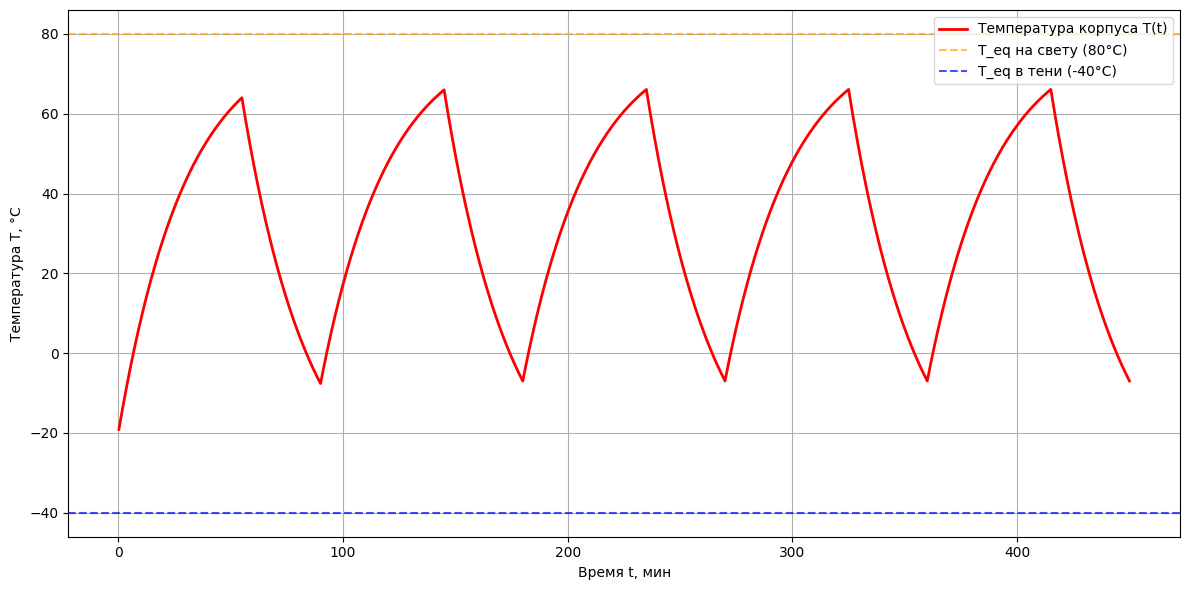

In [34]:
plt.figure(figsize=(12, 6))
plt.plot(t_global, T_global, color='red', linewidth=2, label='Температура корпуса T(t)')
plt.axhline(y=T_sun, color='orange', linestyle='--', alpha=0.7, label='T_eq на свету (80°C)')
plt.axhline(y=T_sh, color='blue', linestyle='--', alpha=0.7, label='T_eq в тени (-40°C)')
plt.xlabel('Время t, мин')
plt.ylabel('Температура T, °C')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

a) Почему температура в конце витка перестает меняться от витка к витку?**

In [35]:
print("Потому что система выходит на периодическую функцию, где приток тепла за виток равен оттоку.")

Потому что система выходит на периодическую функцию, где приток тепла за виток равен оттоку.


б) Что изменится при tau = 5 мин и при tau = 300 мин?

Моделирование для tau = 5

In [36]:
tau_test = 5
T_current = T_0
current_time = 0.0
t_gl_5, T_gl_5 = [], []

Задание и решение ОДУ для участка света и тени

In [37]:
ode_sun_5 = Eq(T(s).diff(s) + T(s)/tau_test, T_sun/tau_test)
expr_sun_5 = dsolve(ode_sun_5, T(s), ics={T(0): T_start}).rhs
ode_sh_5 = Eq(T(s).diff(s) + T(s)/tau_test, T_sh/tau_test)
expr_sh_5 = dsolve(ode_sh_5, T(s), ics={T(0): T_start}).rhs
f_sun_5 = lambdify((s, T_start), expr_sun_5, 'numpy')
f_sh_5 = lambdify((s, T_start), expr_sh_5, 'numpy')
expr_sun_5
expr_sh_5

(T_start + 40.0)*exp(-0.2*s) - 40.0

Цикл для моделирования 3-х витков

In [38]:
for _ in range(3):
    s_sun = np.linspace(0, t_sun, 200)
    T_vals_sun = f_sun_5(s_sun, T_current)
    t_gl_5.extend(current_time + s_sun[1:])
    T_gl_5.extend(T_vals_sun[1:])
    T_current = T_vals_sun[-1]
    current_time += t_sun

    s_sh = np.linspace(0, t_sh, 200)
    T_vals_sh = f_sh_5(s_sh, T_current)
    t_gl_5.extend(current_time + s_sh[1:])
    T_gl_5.extend(T_vals_sh[1:])
    T_current = T_vals_sh[-1]
    current_time += t_sh

Моделирование для tau = 300

In [39]:
tau_test = 300
T_current = T_0
current_time = 0.0
t_gl_300, T_gl_300 = [], []

Задание и решение ОДУ для участка света и тени

In [40]:
ode_sun_300 = Eq(T(s).diff(s) + T(s)/tau_test, T_sun/tau_test)
expr_sun_300 = dsolve(ode_sun_300, T(s), ics={T(0): T_start}).rhs
ode_sh_300 = Eq(T(s).diff(s) + T(s)/tau_test, T_sh/tau_test)
expr_sh_300 = dsolve(ode_sh_300, T(s), ics={T(0): T_start}).rhs

f_sun_300 = lambdify((s, T_start), expr_sun_300, 'numpy')
f_sh_300 = lambdify((s, T_start), expr_sh_300, 'numpy')

expr_sun_300
expr_sh_300

(T_start + 40.0)*exp(-0.00333333333333333*s) - 40.0

Цикл для моделирования 3-х витков

> Добавить блок с цитатой



In [41]:
for _ in range(3):
    s_sun = np.linspace(0, t_sun, 200)
    T_vals_sun = f_sun_300(s_sun, T_current)
    t_gl_300.extend(current_time + s_sun[1:])
    T_gl_300.extend(T_vals_sun[1:])
    T_current = T_vals_sun[-1]
    current_time += t_sun
    s_sh = np.linspace(0, t_sh, 200)
    T_vals_sh = f_sh_300(s_sh, T_current)
    t_gl_300.extend(current_time + s_sh[1:])
    T_gl_300.extend(T_vals_sh[1:])
    T_current = T_vals_sh[-1]
    current_time += t_sh

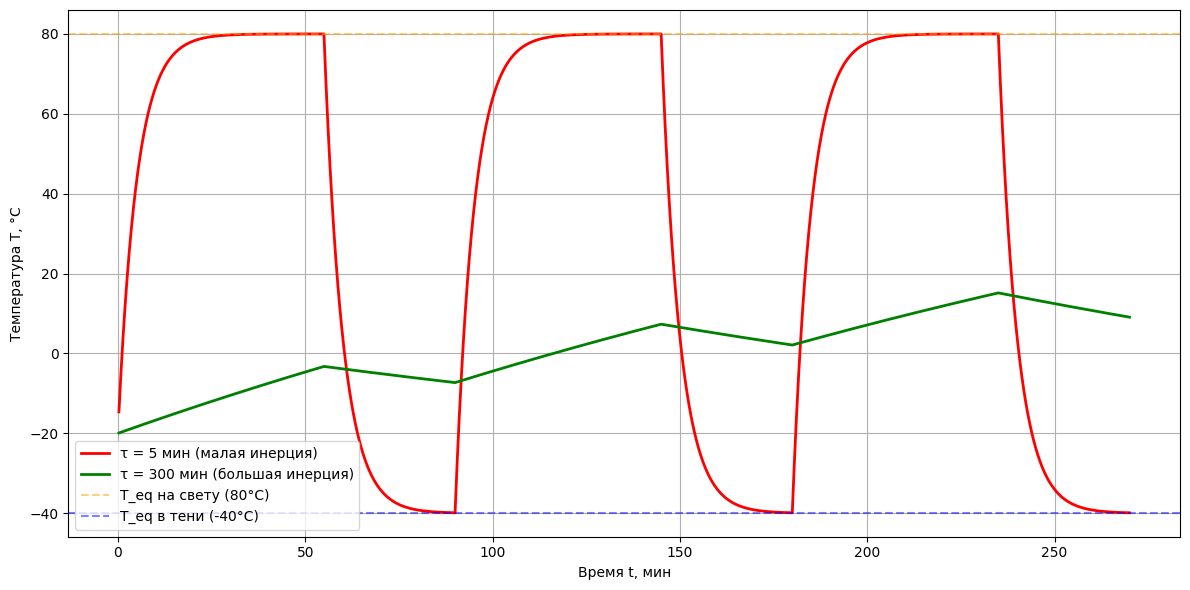

In [42]:
plt.figure(figsize=(12, 6))
plt.plot(t_gl_5, T_gl_5, color='red', linewidth=2, label='τ = 5 мин (малая инерция)')
plt.plot(t_gl_300, T_gl_300, color='green', linewidth=2, label='τ = 300 мин (большая инерция)')
plt.axhline(y=T_sun, color='orange', linestyle='--', alpha=0.5, label='T_eq на свету (80°C)')
plt.axhline(y=T_sh, color='blue', linestyle='--', alpha=0.5, label='T_eq в тени (-40°C)')
plt.xlabel('Время t, мин')
plt.ylabel('Температура T, °C')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
print("При tau = 5 мин cпутник быстро реагирует на изменение освещенности. Температура очень быстро достигает 80°C на свету и -40°C в тени. Амплитуда колебаний максимальная.")
print("При tau = 300 мин cпутник медленно накапливает и отдает тепло. За 55 минут на свету и 35 минут в тени температура не успевает дойти до крайних значений.")

При tau = 5 мин cпутник быстро реагирует на изменение освещенности. Температура очень быстро достигает 80°C на свету и -40°C в тени. Амплитуда колебаний максимальная.
При tau = 300 мин cпутник медленно накапливает и отдает тепло. За 55 минут на свету и 35 минут в тени температура не успевает дойти до крайних значений.
